MRI Volume Shape: (176, 188, 144)
Single Voxel Volume: 0.956 mm³


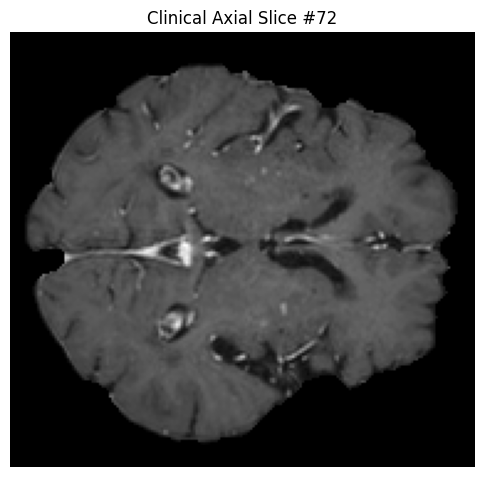

NameError: name 'slice_3d_z' is not defined

In [3]:
!pip install -q nibabel nilearn scikit-image
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
from scipy.ndimage import label
from skimage.filters import threshold_otsu

!wget -q -O brain_sample.nii.gz https://github.com/neurolabusc/niivue-images/raw/main/MR_Gd.nii.gz
img_obj=nib.load("brain_sample.nii.gz")
mri_data = img_obj.get_fdata()

voxel_dims=img_obj.header.get_zooms()
voxel_volume_mm3=voxel_dims[0]*voxel_dims[1]*voxel_dims[2]

print("MRI Volume Shape:",mri_data.shape)
print(f"Single Voxel Volume: {voxel_volume_mm3:.3f} mm³")

slice_idx = mri_data.shape[2] // 2
slice_2d = mri_data[:, :, slice_idx]

plt.figure(figsize=(6, 6))
plt.imshow(slice_2d, cmap="gray")
plt.title(f"Clinical Axial Slice #{slice_idx}")
plt.axis("off")
plt.show()

total_tumor_pixels=0

for z in range(mri_data.shape[2]):
    Slice_3d_z=mri_data[ :,:,z]
    if np.max(Slice_3d_z)==0:
      continue

    norm_z=(slice_3d_z - np.min(slice_3d_z))/(np.max(slice_3d_z)-np.min(slice_3d_z)+1e-8)

    try:
       thresh_z=threshold_otsu(norm_z)
       mask_z=norm_z>thresh_z

       labeled_z, _ = label(mask_z)
       sizes=np.bincount(labeled_z.ravel())
       if len(sizes)>1:
          sizes[0]=0
          brain_z = (labeled_z == np.argmax(sizes))
       else:
          brain_z=mask_z
       brain_pixels=norm_z[brain_z]
       if len(brain_pixels)>0:
           tumor_thresh=np.percentile(brain_pixels,92)
           tumor_mask_z=(norm_z>tumor_thresh)&brain_z
           total_tumor_pixels += np.sum(tumor_mask_z)

    except Exception:
        continue

total_volume_mm3 = total_tumor_pixels * voxel_volume_mm3

total_volume_cm3 = total_volume_mm3 / 1000.0

print(f"Calculated Clinical Lesion / Tumor Volume: {total_volume_cm3:.2f} cm³")
